# ECG Arrhythmia Classification - EDA and ML Baselines

## Overview

This notebook explores the ECG Heartbeat Categorization Dataset and establishes traditional machine learning baselines for arrhythmia classification.

The objective is to understand the dataset, investigate its characteristics, perform exploratory data analysis and evaluate conventional machine learning algorithms.

The experiments in this notebook provide a performance reference against which the subsequent deep learning architectures can be compared.

The dataset contains ECG heartbeat signals derived from the MIT-BIH Arrhythmia Database and consists of five classification categories.


## 1. Objectives

The main objectives of this notebook are:

1. Load and inspect the ECG dataset.
2. Understand the structure and distribution of the five classes.
3. Perform exploratory data analysis on ECG signals.
4. Identify missing values, duplicate records and other data-quality issues.
5. Prepare training and validation datasets using stratified splitting.
6. Apply appropriate feature scaling.
7. Train traditional machine learning classification models.
8. Evaluate and compare baseline model performance.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## 2. Dataset Description

The project uses the ECG Heartbeat Categorization Dataset by Shayan Fazeli, derived from the MIT-BIH Arrhythmia Database.

The dataset contains two CSV files:

- `mitbih_train.csv`
- `mitbih_test.csv`

Each record consists of 188 columns:

- The first 187 columns represent numerical ECG signal samples.
- The final column represents the target class.

### Class Labels

| Label | Class |
|---|---|
| 0 | Normal |
| 1 | Supraventricular |
| 2 | Ventricular |
| 3 | Fusion |
| 4 | Unknown |

The classification task involves identifying the heartbeat category from its corresponding ECG signal.


In [2]:
train_df  = pd.read_csv("../data/raw/mitbih_train.csv",header=None)
train_df.head()

,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,0.977941,0.926471,0.681373,0.245098,0.154412,0.191176,0.151961,0.085784,0.058824,0.049020,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 3. Initial Data Inspection

The dataset is inspected to understand its dimensions, feature types, statistical properties and overall structure.

The following checks are performed:

- Dataset dimensions and column information.
- Descriptive statistics of signal features.
- Missing-value inspection.
- Duplicate-record inspection.
- Infinite-value inspection.

These checks help establish the quality and suitability of the dataset before model development.

In [ ]:
print("Missing values:", train_df.isnull().sum())
print("Duplicate rows:", train_df.duplicated().sum())
print("Infinite values:", np.isinf(train_df.to_numpy()).sum())

Missing values: 0
Duplicate rows: 0
Infinite values: 0


In [4]:
class_counts = train_df[187].value_counts().sort_index()

print(class_counts)

187
0.0    72471
1.0     2223
2.0     5788
3.0      641
4.0     6431
Name: count, dtype: int64


## 4. Exploratory Data Analysis

Exploratory data analysis is performed to understand the distribution and characteristics of ECG heartbeat signals.

### 4.1 Class Distribution

The number of samples belonging to each heartbeat category is examined.

The dataset is highly imbalanced, with the Normal category representing the majority of samples, while Fusion and Supraventricular categories have significantly fewer observations.

This imbalance is an important consideration during model training and evaluation.

### 4.2 ECG Signal Visualization

Representative ECG signals from all five categories are visualized.

This allows a basic comparison of waveform patterns and demonstrates the variation in signal morphology between heartbeat categories.

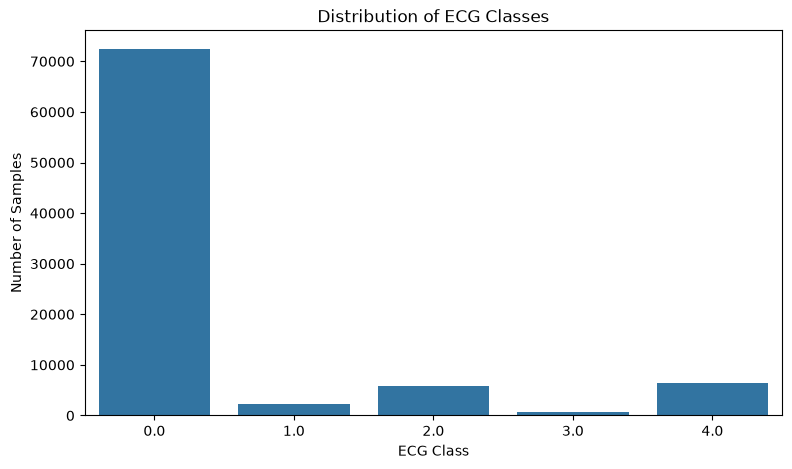

In [5]:
plt.figure(figsize=(9, 5))

sns.barplot(x=class_counts.index,y=class_counts.values
)

plt.xlabel("ECG Class")
plt.ylabel("Number of Samples")
plt.title("Distribution of ECG Classes")
plt.show()

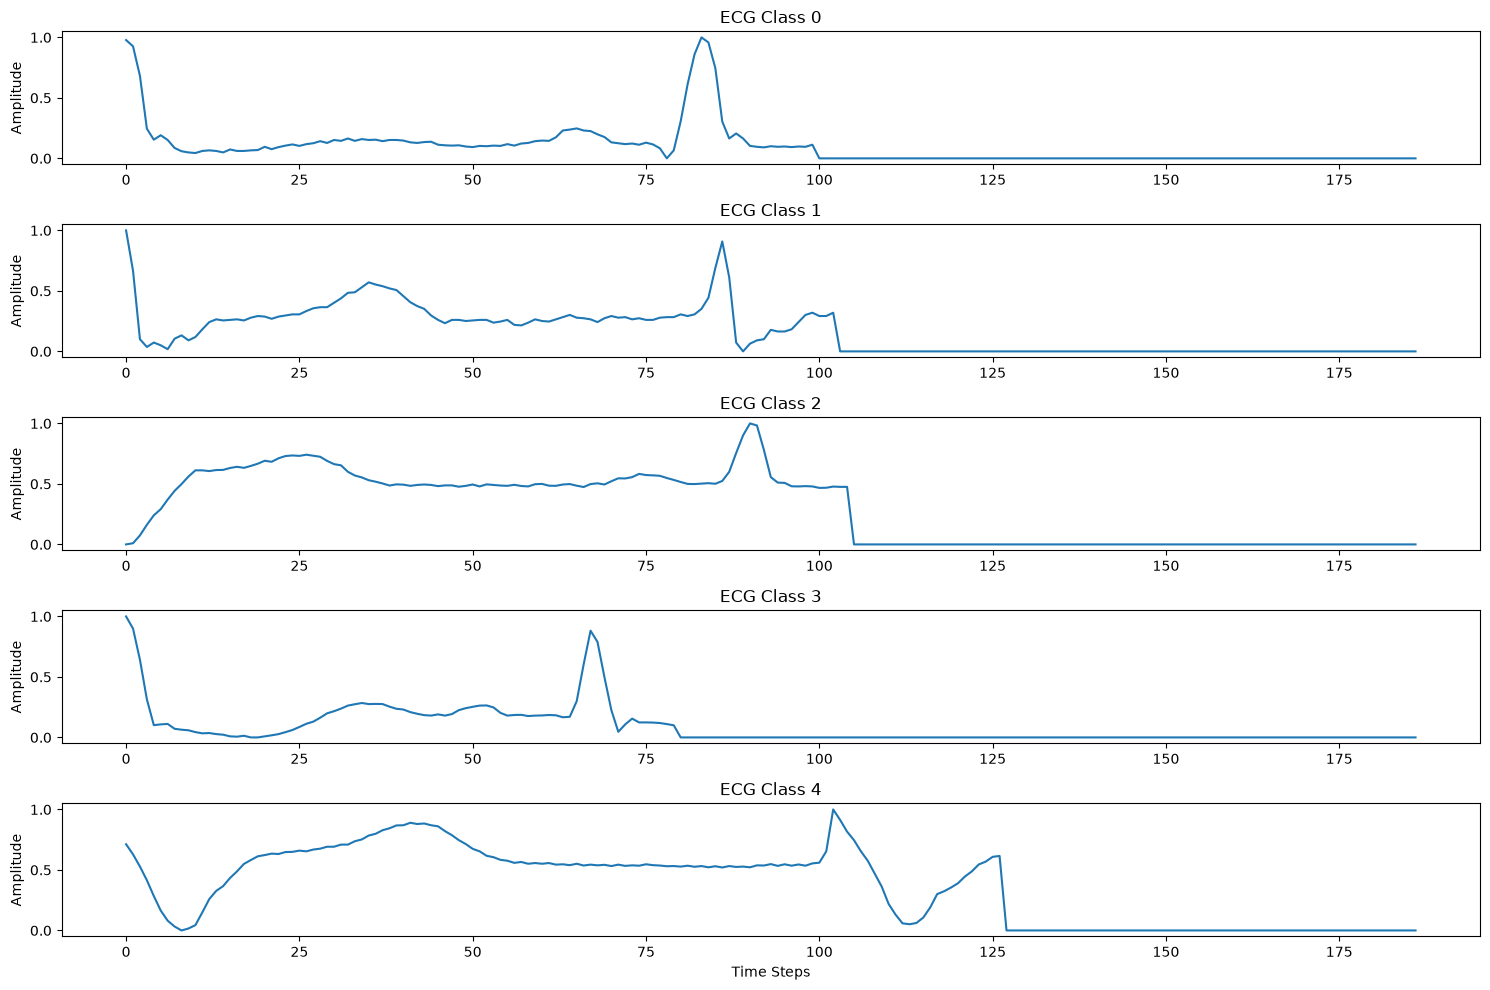

In [6]:
plt.figure(figsize=(15, 10))

for i in range(5):
    signal = train_df[train_df[187] == i].iloc[0, :-1].values

    plt.subplot(5, 1, i + 1)
    plt.plot(signal)
    plt.title(f"ECG Class {i}")
    plt.ylabel("Amplitude")

plt.xlabel("Time Steps")
plt.tight_layout()
plt.show()

In [7]:
class_counts = train_df[187].value_counts().sort_index()

class_percentage = (class_counts / len(train_df)) * 100

print(class_percentage)

187
0.0    82.772917
1.0     2.539005
2.0     6.610777
3.0     0.732120
4.0     7.345181
Name: count, dtype: float64


In [8]:
signals = train_df.iloc[:, :-1]

print("Minimum:", signals.min().min())
print("Maximum:", signals.max().max())
print("Mean:", signals.mean().mean())
print("Standard deviation:", signals.std().mean())

Minimum: 0.0
Maximum: 1.0
Mean: 0.17428295254906376
Standard deviation: 0.17542948924983826


## 5. Train-Validation Split

The original training dataset is divided into training and validation subsets using stratified sampling.

An 85:15 split is used with a fixed random state of 42.

Stratification ensures that the relative class distribution is maintained across both subsets.

The resulting training and validation indices are saved and reused across all model experiments to ensure a consistent evaluation setup.

The original Kaggle test dataset is kept separate for final evaluation.

In [9]:
X = train_df.iloc[:,:-1]
y = train_df.iloc[:,-1]

In [10]:
print(X.shape)
print(y.shape)

(87554, 187)
(87554,)


In [11]:
train_idx = np.load("../data/processed/train_idx.npy")
val_idx = np.load("../data/processed/val_idx.npy")


train_X = X.iloc[train_idx]
val_X = X.iloc[val_idx]

train_y = y.iloc[train_idx]
val_y = y.iloc[val_idx]

## 6. Data Preprocessing

Feature scaling is applied where required by the selected algorithms.

The scaler is fitted only on the training data and subsequently used to transform the validation data.

This prevents information from the validation set from influencing the fitted preprocessing parameters.

Tree-based algorithms such as Random Forest do not require feature scaling, whereas Logistic Regression benefits from standardized input features.


In [12]:
scaler = StandardScaler()
scaled_train_X = scaler.fit_transform(train_X)
scaled_val_X = scaler.transform(val_X)

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score,classification_report,confusion_matrix,ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

## 7. Traditional Machine Learning Baselines

Three traditional machine learning approaches are evaluated.

### 7.1 Dummy Classifier

The Dummy Classifier acts as a reference baseline by generating predictions using a simple predefined strategy without learning meaningful relationships from ECG features.

### 7.2 Logistic Regression

Logistic Regression is used as a linear classification baseline.

It estimates class probabilities based on a linear combination of input features.

Feature scaling is applied before training.

### 7.3 Random Forest

Random Forest is an ensemble learning algorithm that combines multiple decision trees.

It can capture nonlinear relationships and interactions between ECG signal features without requiring standardization.

In [14]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(train_X, train_y)
dummy_pred = dummy.predict(val_X)

In [18]:
params = {"C":[0.01,0.1,1,10],"solver":["lbfgs"],"max_iter":[1000,2000],"class_weight":["balanced"]}

random_search = RandomizedSearchCV(LogisticRegression(),params,cv=5,n_iter=10,n_jobs=-1,random_state=42) 
random_search.fit(scaled_train_X,train_y)
best_lr_model = random_search.best_estimator_
lr_pred = best_lr_model.predict(scaled_val_X)

In [22]:
params = {"n_estimators":[100,200,300],"max_depth":[10,20,None],"min_samples_split":[2,5],"min_samples_leaf":[1,2],"max_features":["sqrt","log2"],"class_weight":["balanced"]}

random_search = RandomizedSearchCV(RandomForestClassifier(),params,cv=5,n_iter=10,n_jobs=-1,random_state=42) 
random_search.fit(train_X,train_y)
best_rf_model = random_search.best_estimator_
rf_pred = best_rf_model.predict(val_X)

## 8. Model Evaluation

The trained models are evaluated on the validation dataset.

The following metrics are considered:

- Accuracy
- Precision
- Recall
- F1-score
- Macro-F1
- Weighted-F1

Classification reports and confusion matrices are generated to understand overall and class-wise performance.

Macro-F1 receives particular attention because the dataset contains significant class imbalance.

In [15]:
print("Accuracy:", accuracy_score(val_y, dummy_pred))
print("Macro F1:", f1_score(val_y, dummy_pred, average="macro"))
print("Balanced Accuracy:", balanced_accuracy_score(val_y, dummy_pred))

Accuracy: 0.8277621259422828
Macro F1: 0.1811531411431428
Balanced Accuracy: 0.2


In [16]:
print("Dummy Classifier")
print(classification_report(val_y, dummy_pred, digits=3))

Dummy Classifier
              precision    recall  f1-score   support

         0.0      0.828     1.000     0.906     10871
         1.0      0.000     0.000     0.000       333
         2.0      0.000     0.000     0.000       868
         3.0      0.000     0.000     0.000        97
         4.0      0.000     0.000     0.000       964

    accuracy                          0.828     13133
   macro avg      0.166     0.200     0.181     13133
weighted avg      0.685     0.828     0.750     13133



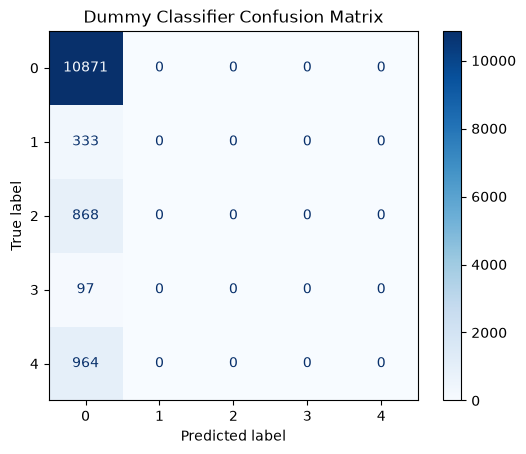

In [17]:
cm = confusion_matrix(val_y, dummy_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2, 3, 4]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Dummy Classifier Confusion Matrix")
plt.show()

In [19]:
print("Accuracy:", accuracy_score(val_y, lr_pred))
print("Macro F1:", f1_score(val_y, lr_pred, average="macro"))
print("Balanced Accuracy:", balanced_accuracy_score(val_y, lr_pred))

Accuracy: 0.6734181070585548
Macro F1: 0.4807037366606798
Balanced Accuracy: 0.7622331234682791


In [20]:
print("Logistic Regression")
print(classification_report(val_y, lr_pred, digits=3))

Logistic Regression
              precision    recall  f1-score   support

         0.0      0.970     0.646     0.775     10871
         1.0      0.152     0.700     0.250       333
         2.0      0.295     0.738     0.422       868
         3.0      0.079     0.825     0.145        97
         4.0      0.739     0.902     0.812       964

    accuracy                          0.673     13133
   macro avg      0.447     0.762     0.481     13133
weighted avg      0.881     0.673     0.737     13133



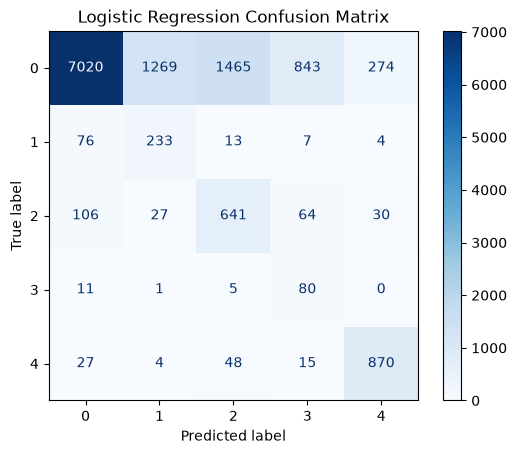

In [21]:
cm = confusion_matrix(val_y, lr_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2, 3, 4]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [23]:
print("Accuracy:", accuracy_score(val_y, rf_pred))
print("Macro F1:", f1_score(val_y, rf_pred, average="macro"))
print("Balanced Accuracy:", balanced_accuracy_score(val_y, rf_pred))

Accuracy: 0.9791365263077743
Macro F1: 0.903677705861768
Balanced Accuracy: 0.8757721310727049


In [24]:
print("Random Forest")
print(classification_report(val_y, rf_pred, digits=3))

Random Forest
              precision    recall  f1-score   support

         0.0      0.984     0.993     0.988     10871
         1.0      0.919     0.751     0.826       333
         2.0      0.941     0.935     0.938       868
         3.0      0.855     0.732     0.789        97
         4.0      0.985     0.968     0.976       964

    accuracy                          0.979     13133
   macro avg      0.937     0.876     0.904     13133
weighted avg      0.979     0.979     0.979     13133



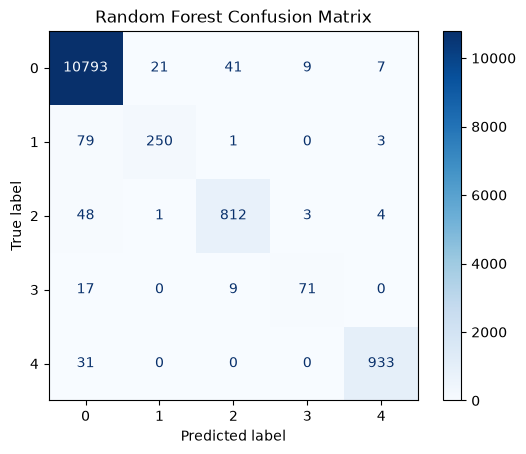

In [25]:
cm = confusion_matrix(val_y, rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2, 3, 4]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [26]:
results = []

models = {
    "Dummy Classifier": dummy_pred,
    "Logistic Regression": lr_pred,
    "Random Forest": rf_pred
}

for name, predictions in models.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(val_y, predictions),
        "Macro F1": f1_score(val_y, predictions, average="macro"),
        "Balanced Accuracy": balanced_accuracy_score(val_y, predictions)
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Macro F1,Balanced Accuracy
0,Dummy Classifier,0.827762,0.181153,0.200000
1,Logistic Regression,0.673418,0.480704,0.762233
2,Random Forest,0.979137,0.903678,0.875772


In [27]:
from pathlib import Path
import json

metrics_dir = Path("../results/metrics")
figures_dir = Path("../results/figures")
metrics_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(metrics_dir / "baselines.csv", index=False)

In [28]:
class_names = ["N", "S", "V", "F", "Q"]
models = {
    "dummy": dummy_pred,
    "logistic_regression": lr_pred,
    "random_forest": rf_pred,
}

for name, preds in models.items():
    report = classification_report(
        val_y, preds, target_names=class_names, digits=3, output_dict=True
    )
    pd.DataFrame(report).T.to_csv(metrics_dir / f"per_class_{name}.csv")

In [29]:
for name, preds in models.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        val_y, preds, display_labels=class_names,
        normalize="true", cmap="Blues", ax=ax
    )
    ax.set_title(f"{name} (row-normalized)")
    fig.savefig(figures_dir / f"confusion_{name}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)

In [30]:
best_params = {
    "logistic_regression": best_lr_model.get_params(),
    "random_forest": best_rf_model.get_params(),
}
with open(metrics_dir / "baseline_best_params.json", "w") as f:
    json.dump(best_params, f, indent=2, default=str)

In [31]:
import joblib
Path("../models").mkdir(exist_ok=True)
joblib.dump(best_lr_model, "../models/baseline_lr.joblib")
joblib.dump(best_rf_model, "../models/baseline_rf.joblib")

['../models/baseline_rf.joblib']

## 9. Conclusion

This notebook establishes the exploratory and traditional machine learning foundation for ECG arrhythmia classification.

The dataset analysis reveals substantial class imbalance, making class-wise evaluation essential.

The Dummy Classifier, Logistic Regression and Random Forest provide baseline performance references for the subsequent deep learning experiments.

The same stratified training and validation split is reused in the CNN, LSTM and GRU experiments to maintain consistency across model comparisons.